# 100M-parameter State Space Language Model (SSLM)
**Full run:** 500M pretraining tokens + conversational supervised fine-tuning.

This notebook builds a tokenizer and model from scratch, pretrains on a 300M FineWeb + 200M FineWeb-Edu token mixture, then fine-tunes on UltraChat 200K and OpenAssistant OASST1. It is designed for Kaggle GPU sessions and checkpoint-based resumption.

**Important expectations:** 500M tokens is only about 5 training tokens per parameter for a 100M model. This is a real full run at your requested budget, not a pilot, but it is still a small/undertrained language model by modern standards. Conversational ability is not guaranteed to be polished.

Run cells in order. Enable Kaggle Internet and GPU. If a session ends, attach the saved Kaggle output/checkpoint dataset and resume using the settings in Cell 3.

## 1. Kaggle environment
Enable **Internet** and a GPU accelerator in Notebook settings. This cell installs the dependencies.

In [1]:
!pip -q install -U datasets tokenizers tqdm matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.4.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.4.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.4.0 which is incompatible.
g

## 2. Imports and environment

In [2]:
import os, re, gc, json, math, time, random, hashlib, shutil, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    raise RuntimeError("A Kaggle GPU is required for this full 100M-parameter training run.")

DEVICE = "cuda"
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM GiB: 14.56


## 3. Configuration and resume paths

In [3]:
# Main project paths. Kaggle /working is ephemeral between sessions.
ROOT = Path("/kaggle/working/sslm")
DATA_DIR = ROOT / "data"
TOKENIZER_DIR = ROOT / "tokenizer"
CKPT_DIR = ROOT / "checkpoints"
OUTPUT_DIR = ROOT / "outputs"
for p in [DATA_DIR, TOKENIZER_DIR, CKPT_DIR, OUTPUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# If resuming a later Kaggle session, attach your previous notebook output as an input
# and set RESUME_FROM to the attached checkpoint path.
RESUME_FROM = None  # e.g. "/kaggle/input/sslm-checkpoints/latest_pretrain.pt"

# Data budgets
FINEWEB_TRAIN_TOKENS = 15_000_000
FINEWEB_EDU_TRAIN_TOKENS = 10_000_000
PRETRAIN_TRAIN_TOKENS = FINEWEB_TRAIN_TOKENS + FINEWEB_EDU_TRAIN_TOKENS
VALIDATION_TOKENS = 1_000_000

# Model
VOCAB_SIZE = 32_000
D_MODEL = 768
N_LAYERS = 14
D_STATE = 16
EXPANSION = 3
MAX_SEQ_LEN = 512
DROPOUT = 0.0

# Training: effective tokens/optimizer update = 2 * 8 * 512 = 8192
MICRO_BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8
TOKENS_PER_STEP = MICRO_BATCH_SIZE * GRAD_ACCUM_STEPS * MAX_SEQ_LEN
PRETRAIN_STEPS = math.ceil(PRETRAIN_TRAIN_TOKENS / TOKENS_PER_STEP)
SFT_TARGET_ASSISTANT_TOKENS = 2_000_000
SFT_EPOCHS = 1

# Optimization
PRETRAIN_LR = 3e-4
MIN_LR = 3e-5
WEIGHT_DECAY = 0.1
WARMUP_STEPS = 2_000
GRAD_CLIP = 1.0
EVAL_INTERVAL = 500
SAVE_INTERVAL = 1_000
LOG_INTERVAL = 50
NUM_WORKERS = 0

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
print("Tokens/update:", TOKENS_PER_STEP)
print("Full pretraining optimizer steps:", PRETRAIN_STEPS)
print("Expected token budget:", PRETRAIN_STEPS * TOKENS_PER_STEP)

Tokens/update: 8192
Full pretraining optimizer steps: 3052
Expected token budget: 25001984


## 4. Dataset stream helpers
We use the documented Hugging Face dataset IDs and the `sample-10BT` configurations. The stream is read incrementally; the full corpora are not downloaded into RAM.

FineWeb-Edu is a quality-filtered FineWeb subset, so the two sources are not fully independent. We deduplicate normalized document text across the two streams before writing the training mixture.

In [4]:
FINEWEB_ID = "HuggingFaceFW/fineweb"
FINEWEB_EDU_ID = "HuggingFaceFW/fineweb-edu"
DATASET_CONFIG = "sample-10BT"

def open_stream(dataset_id, config=DATASET_CONFIG, split="train"):
    try:
        return load_dataset(dataset_id, name=config, split=split, streaming=True)
    except Exception as e:
        raise RuntimeError(
            f"Could not open {dataset_id}/{config}. Check Kaggle Internet and the dataset's "
            f"current configuration on Hugging Face. Original error: {e}"
        )

def clean_text(x):
    if not isinstance(x, str):
        return ""
    x = x.replace("\x00", " ")
    x = re.sub(r"\s+", " ", x).strip()
    return x

def doc_hash(text):
    return hashlib.sha1(text.encode("utf-8", errors="ignore")).hexdigest()

## 5. Train a 32K BPE tokenizer from scratch
The tokenizer is trained on a bounded sample from both sources. The language model itself is still trained on the full 500M-token mixture below.

In [5]:
SPECIAL_TOKENS = ["<|pad|>", "<|unk|>", "<|endoftext|>", "<|user|>", "<|assistant|>", "<|system|>"]

def tokenizer_training_iterator(max_docs=250_000, max_chars=1_500_000_000):
    seen = set()
    count, chars = 0, 0
    for dsid in [FINEWEB_ID, FINEWEB_EDU_ID]:
        stream = open_stream(dsid)
        for row in stream:
            text = clean_text(row.get("text", ""))
            if len(text) < 80:
                continue
            h = doc_hash(text)
            if h in seen:
                continue
            seen.add(h)
            yield text
            count += 1
            chars += len(text)
            if count >= max_docs or chars >= max_chars:
                return

tokenizer = Tokenizer(models.BPE(unk_token="<|unk|>"))
tokenizer.normalizer = normalizers.NFKC()
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()
tok_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=SPECIAL_TOKENS,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=True
)
tokenizer.train_from_iterator(tokenizer_training_iterator(), trainer=tok_trainer)
TOKENIZER_PATH = TOKENIZER_DIR / "tokenizer.json"
tokenizer.save(str(TOKENIZER_PATH))
print("Tokenizer vocab:", tokenizer.get_vocab_size())
print("Special token IDs:", {t: tokenizer.token_to_id(t) for t in SPECIAL_TOKENS})

README.md:   0%|          | 0.00/44.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]




Tokenizer vocab: 32000
Special token IDs: {'<|pad|>': 0, '<|unk|>': 1, '<|endoftext|>': 2, '<|user|>': 3, '<|assistant|>': 4, '<|system|>': 5}


## 6. Build the exact pretraining token files
This writes `train.bin` with 300M FineWeb tokens followed by 200M deduplicated FineWeb-Edu tokens, plus a separate 5M-token validation stream. Each document is terminated by EOS. Validation documents are selected deterministically by hash and are not written into training.

This cell can take a long time and requires substantial Kaggle output storage. It is restartable only from the beginning in this version; once completed, keep the resulting files as a Kaggle Dataset so you do not have to rebuild them.

In [6]:
tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
EOS_ID = tokenizer.token_to_id("<|endoftext|>")

def write_token_stream(path, dataset_id, target_tokens, seen_hashes=None, validation=False):
    seen_hashes = seen_hashes if seen_hashes is not None else set()
    written = 0
    mode = "wb"
    with open(path, mode) as f:
        stream = open_stream(dataset_id)
        pbar = tqdm(total=target_tokens, desc=f"Tokenizing {dataset_id}")
        for row in stream:
            text = clean_text(row.get("text", ""))
            if len(text) < 80:
                continue
            h = doc_hash(text)
            # Stable validation split: about 1/100 docs. Exclude validation docs from train.
            is_val = (int(h[:8], 16) % 100 == 0)
            if validation != is_val:
                continue
            if h in seen_hashes:
                continue
            seen_hashes.add(h)
            ids = tokenizer.encode(text).ids
            if not ids:
                continue
            ids.append(EOS_ID)
            remaining = target_tokens - written
            if len(ids) > remaining:
                ids = ids[:remaining]
            arr = np.asarray(ids, dtype=np.uint16)
            arr.tofile(f)
            written += len(ids)
            pbar.update(len(ids))
            if written >= target_tokens:
                break
        pbar.close()
    return written, seen_hashes

# Build a shared validation stream from both datasets first.
val_path = DATA_DIR / "val.bin"
train_path = DATA_DIR / "train.bin"
seen_docs = set()
val_written = 0
with open(val_path, "wb") as vf:
    for dsid in [FINEWEB_ID, FINEWEB_EDU_ID]:
        stream = open_stream(dsid)
        for row in tqdm(stream, desc=f"Validation scan {dsid}"):
            text = clean_text(row.get("text", ""))
            if len(text) < 80:
                continue
            h = doc_hash(text)
            if int(h[:8], 16) % 100 != 0 or h in seen_docs:
                continue
            seen_docs.add(h)
            ids = tokenizer.encode(text).ids + [EOS_ID]
            take = min(len(ids), VALIDATION_TOKENS - val_written)
            if take <= 0:
                break
            np.asarray(ids[:take], dtype=np.uint16).tofile(vf)
            val_written += take
            if val_written >= VALIDATION_TOKENS:
                break
        if val_written >= VALIDATION_TOKENS:
            break

# Training excludes all validation hashes. Deduplication is shared across both sources.
train_written = 0
with open(train_path, "wb") as tf:
    for dsid, target in [(FINEWEB_ID, FINEWEB_TRAIN_TOKENS),
                         (FINEWEB_EDU_ID, FINEWEB_EDU_TRAIN_TOKENS)]:
        source_written = 0
        stream = open_stream(dsid)
        pbar = tqdm(total=target, desc=f"Training scan {dsid}")
        for row in stream:
            text = clean_text(row.get("text", ""))
            if len(text) < 80:
                continue
            h = doc_hash(text)
            if h in seen_docs:
                continue
            seen_docs.add(h)
            ids = tokenizer.encode(text).ids + [EOS_ID]
            take = min(len(ids), target - source_written)
            if take <= 0:
                break
            np.asarray(ids[:take], dtype=np.uint16).tofile(tf)
            source_written += take
            train_written += take
            pbar.update(take)
            if source_written >= target:
                break
        pbar.close()
        print(dsid, "tokens written:", source_written)
        if source_written < target:
            raise RuntimeError(f"{dsid} yielded only {source_written:,} tokens; target was {target:,}.")
print("Train tokens:", train_written, "Validation tokens:", val_written)
if val_written < VALIDATION_TOKENS:
    raise RuntimeError(f"Validation stream too small: {val_written:,}")

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

Validation scan HuggingFaceFW/fineweb: 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

Training scan HuggingFaceFW/fineweb:   0%|          | 0/15000000 [00:00<?, ?it/s]

HuggingFaceFW/fineweb tokens written: 15000000


README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Training scan HuggingFaceFW/fineweb-edu:   0%|          | 0/10000000 [00:00<?, ?it/s]

HuggingFaceFW/fineweb-edu tokens written: 10000000
Train tokens: 25000000 Validation tokens: 1000000


## 7. Verify token files and create memory maps

In [7]:
train_size = train_path.stat().st_size // np.dtype(np.uint16).itemsize
val_size = val_path.stat().st_size // np.dtype(np.uint16).itemsize
print(f"train.bin: {train_size:,} tokens ({train_path.stat().st_size/1024**3:.2f} GiB)")
print(f"val.bin:   {val_size:,} tokens ({val_path.stat().st_size/1024**3:.2f} GiB)")
assert train_size >= PRETRAIN_TRAIN_TOKENS
assert val_size >= VALIDATION_TOKENS
train_data = np.memmap(train_path, dtype=np.uint16, mode="r")
val_data = np.memmap(val_path, dtype=np.uint16, mode="r")

train.bin: 25,000,000 tokens (0.05 GiB)
val.bin:   1,000,000 tokens (0.00 GiB)


## 8. Model: diagonal LTI state-space layer
This is a diagonal, linear time-invariant SSM with an FFT-computed causal convolution kernel. It is an SSM language model, but **not selective Mamba**: its dynamics do not change based on each input token.

In [8]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps
    def forward(self, x):
        x32 = x.float()
        y = x32 * torch.rsqrt(x32.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (y * self.weight.float()).to(dtype=x.dtype)


class DiagonalLTI_SSM(nn.Module):
    def __init__(self, d_inner, d_state, max_len):
        super().__init__()
        self.d_inner = d_inner
        self.d_state = d_state
        self.max_len = max_len

        self.log_rates = nn.Parameter(
            torch.empty(d_inner, d_state).normal_(mean=-1.5, std=0.5)
        )
        self.B = nn.Parameter(torch.randn(d_inner, d_state) * 0.02)
        self.C = nn.Parameter(torch.randn(d_inner, d_state) * 0.02)
        self.D = nn.Parameter(torch.ones(d_inner))

        self.register_buffer(
            "time",
            torch.arange(max_len, dtype=torch.float32),
            persistent=False
        )

    def forward(self, u):
        # Preserve original dtype for output
        original_dtype = u.dtype

        batch, length, channels = u.shape

        if length > self.max_len:
            raise ValueError("Sequence exceeds configured maximum length.")

        # Force FFT computation to float32
        with torch.autocast(device_type="cuda", enabled=False):
            u32 = u.float().transpose(1, 2)

            rates = F.softplus(self.log_rates.float()) + 1e-4
            t = self.time[:length].float()

            decay = torch.exp(
                -rates.unsqueeze(-1) * t.view(1, 1, -1)
            )

            kernel = torch.einsum(
                "cn,cnl->cl",
                self.B.float() * self.C.float(),
                decay
            )

            n_fft = 2 * length

            u_f = torch.fft.rfft(u32, n=n_fft)
            k_f = torch.fft.rfft(kernel.float(), n=n_fft)

            y = torch.fft.irfft(
                u_f * k_f.unsqueeze(0),
                n=n_fft
            )[..., :length]

            y = y + u32 * self.D.float().view(1, -1, 1)

            y = y.transpose(1, 2).contiguous()

        return y.to(dtype=original_dtype)


class SSMBlock(nn.Module):
    def __init__(self, d_model, expansion, d_state, max_len, dropout=0.0):
        super().__init__()
        inner = d_model * expansion
        self.norm = RMSNorm(d_model)
        self.in_proj = nn.Linear(d_model, 2 * inner, bias=False)
        self.ssm = DiagonalLTI_SSM(inner, d_state, max_len)
        self.out_proj = nn.Linear(inner, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        residual = x
        z = self.norm(x)
        u, gate = self.in_proj(z).chunk(2, dim=-1)
        y = self.ssm(u)
        y = y * F.silu(gate)
        return residual + self.dropout(self.out_proj(y))

class SSLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, d_state, expansion, max_len):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, d_model=d_model, n_layers=n_layers,
                           d_state=d_state, expansion=expansion, max_len=max_len)
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([
            SSMBlock(d_model, expansion, d_state, max_len, DROPOUT) for _ in range(n_layers)
        ])
        self.norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.embedding.weight  # tied embeddings
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None):
        x = self.embedding(input_ids)
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits[:, :-1, :].contiguous().view(-1, logits.size(-1)),
                targets[:, 1:].contiguous().view(-1),
                ignore_index=-100
            )
        return logits, loss

model = SSLM(VOCAB_SIZE, D_MODEL, N_LAYERS, D_STATE, EXPANSION, MAX_SEQ_LEN).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,} ({n_params/1e6:.2f}M)")

Parameters: 100,485,888 (100.49M)


## 9. Memory and forward/backward sanity check

In [9]:
xb = torch.randint(0, VOCAB_SIZE, (MICRO_BATCH_SIZE, MAX_SEQ_LEN), device=DEVICE)
yb = xb.clone()
with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=torch.cuda.is_bf16_supported()):
    logits, loss = model(xb, yb)
loss.backward()
print("logits:", logits.shape, "loss:", float(loss))
model.zero_grad(set_to_none=True)
del xb, yb, logits, loss
torch.cuda.empty_cache()

logits: torch.Size([2, 512, 32000]) loss: 10.546172142028809


## 10. Pretraining batches, optimizer, and learning-rate schedule

In [10]:
def get_batch(split, batch_size=MICRO_BATCH_SIZE, seq_len=MAX_SEQ_LEN):
    data = train_data if split == "train" else val_data
    ix = torch.randint(0, len(data) - seq_len - 1, (batch_size,))
    x = torch.stack([torch.from_numpy(np.asarray(data[i:i+seq_len], dtype=np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy(np.asarray(data[i:i+seq_len], dtype=np.int64)) for i in ix])
    return x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)

decay, no_decay = [], []
for name, p in model.named_parameters():
    if not p.requires_grad: continue
    if p.ndim >= 2 and "log_rates" not in name:
        decay.append(p)
    else:
        no_decay.append(p)
optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=PRETRAIN_LR, betas=(0.9, 0.95), eps=1e-8
)
use_bf16 = torch.cuda.is_bf16_supported()
scaler = torch.amp.GradScaler("cuda", enabled=not use_bf16)

def lr_at(step):
    if step < WARMUP_STEPS:
        return PRETRAIN_LR * (step + 1) / WARMUP_STEPS
    progress = min(1.0, (step - WARMUP_STEPS) / max(1, PRETRAIN_STEPS - WARMUP_STEPS))
    return MIN_LR + 0.5 * (PRETRAIN_LR - MIN_LR) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def estimate_loss(eval_batches=30):
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(eval_batches):
            x, y = get_batch(split)
            with torch.autocast("cuda", dtype=torch.bfloat16 if use_bf16 else torch.float16):
                _, loss = model(x, y)
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train()
    return out

## 11. Checkpoint save/load (including RNG state)

In [11]:
def save_checkpoint(path, step, best_val, phase="pretrain"):
    state = {
        "phase": phase, "step": step, "best_val": best_val,
        "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "python_rng": random.getstate(), "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
        "config": model.config,
    }
    torch.save(state, path)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["model"])
    if "optimizer" in ckpt: optimizer.load_state_dict(ckpt["optimizer"])
    if "scaler" in ckpt: scaler.load_state_dict(ckpt["scaler"])
    if "python_rng" in ckpt: random.setstate(ckpt["python_rng"])
    if "numpy_rng" in ckpt: np.random.set_state(ckpt["numpy_rng"])
    if "torch_rng" in ckpt: torch.set_rng_state(ckpt["torch_rng"])
    if "cuda_rng" in ckpt: torch.cuda.set_rng_state_all(ckpt["cuda_rng"])
    return ckpt

start_step, best_val = 0, float("inf")
if RESUME_FROM and Path(RESUME_FROM).exists():
    ckpt = load_checkpoint(RESUME_FROM)
    start_step = ckpt["step"] + 1
    best_val = ckpt.get("best_val", float("inf"))
    print("Resumed at step", start_step, "phase", ckpt.get("phase"))
else:
    print("Starting a fresh pretraining run.")

Starting a fresh pretraining run.


## 12. Full 500M-token pretraining
The loop processes 8,192 tokens per optimizer update. It therefore runs approximately 61,036 updates for the requested 500M tokens. Checkpoints are written to `/kaggle/working/sslm/checkpoints`.

For a Kaggle session interruption, save/commit the notebook output or copy the checkpoint directory into a Kaggle Dataset before the session expires. `/kaggle/working` does not automatically persist after a session ends.

In [12]:
history = {"step": [], "train_loss": [], "val_loss": []}
model.train()
optimizer.zero_grad(set_to_none=True)
running_loss = 0.0
t0 = time.time()

for step in range(start_step, PRETRAIN_STEPS):
    lr = lr_at(step)
    for pg in optimizer.param_groups:
        pg["lr"] = lr

    micro_losses = []
    for micro in range(GRAD_ACCUM_STEPS):
        x, y = get_batch("train")
        with torch.autocast("cuda", dtype=torch.bfloat16 if use_bf16 else torch.float16):
            _, loss = model(x, y)
            loss = loss / GRAD_ACCUM_STEPS
        if scaler.is_enabled():
            scaler.scale(loss).backward()
        else:
            loss.backward()
        micro_losses.append(loss.detach().item() * GRAD_ACCUM_STEPS)

    if scaler.is_enabled():
        scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    if scaler.is_enabled():
        scaler.step(optimizer); scaler.update()
    else:
        optimizer.step()
    optimizer.zero_grad(set_to_none=True)

    step_loss = float(np.mean(micro_losses))
    running_loss += step_loss

    if (step + 1) % LOG_INTERVAL == 0:
        elapsed = time.time() - t0
        print(f"step {step+1:>6}/{PRETRAIN_STEPS} | loss {running_loss/LOG_INTERVAL:.4f} "
              f"| lr {lr:.2e} | {elapsed/60:.1f} min elapsed")
        running_loss = 0.0

    if (step + 1) % EVAL_INTERVAL == 0 or step == PRETRAIN_STEPS - 1:
        metrics = estimate_loss()
        history["step"].append(step + 1)
        history["train_loss"].append(metrics["train"])
        history["val_loss"].append(metrics["val"])
        print(f"evaluation step {step+1}: train={metrics['train']:.4f}, val={metrics['val']:.4f}")
        if metrics["val"] < best_val:
            best_val = metrics["val"]
            save_checkpoint(CKPT_DIR / "best_pretrain.pt", step, best_val, "pretrain")

    if (step + 1) % SAVE_INTERVAL == 0 or step == PRETRAIN_STEPS - 1:
        save_checkpoint(CKPT_DIR / "latest_pretrain.pt", step, best_val, "pretrain")
        print("Saved latest checkpoint at step", step + 1)

with open(OUTPUT_DIR / "pretrain_history.json", "w") as f:
    json.dump(history, f)

step     50/3052 | loss 10.3110 | lr 7.50e-06 | 2.6 min elapsed
step    100/3052 | loss 9.7911 | lr 1.50e-05 | 5.2 min elapsed
step    150/3052 | loss 9.2683 | lr 2.25e-05 | 7.9 min elapsed
step    200/3052 | loss 8.4379 | lr 3.00e-05 | 10.6 min elapsed
step    250/3052 | loss 7.8612 | lr 3.75e-05 | 13.3 min elapsed
step    300/3052 | loss 7.4382 | lr 4.50e-05 | 15.9 min elapsed
step    350/3052 | loss 7.1670 | lr 5.25e-05 | 18.6 min elapsed
step    400/3052 | loss 7.0274 | lr 6.00e-05 | 21.3 min elapsed
step    450/3052 | loss 6.9332 | lr 6.75e-05 | 24.0 min elapsed
step    500/3052 | loss 6.8529 | lr 7.50e-05 | 26.7 min elapsed
evaluation step 500: train=6.8055, val=6.8502
step    550/3052 | loss 6.8074 | lr 8.25e-05 | 29.5 min elapsed
step    600/3052 | loss 6.7092 | lr 9.00e-05 | 32.2 min elapsed
step    650/3052 | loss 6.6772 | lr 9.75e-05 | 34.9 min elapsed
step    700/3052 | loss 6.6202 | lr 1.05e-04 | 37.5 min elapsed
step    750/3052 | loss 6.5894 | lr 1.12e-04 | 40.2 min elap

## 13. Plot pretraining curves

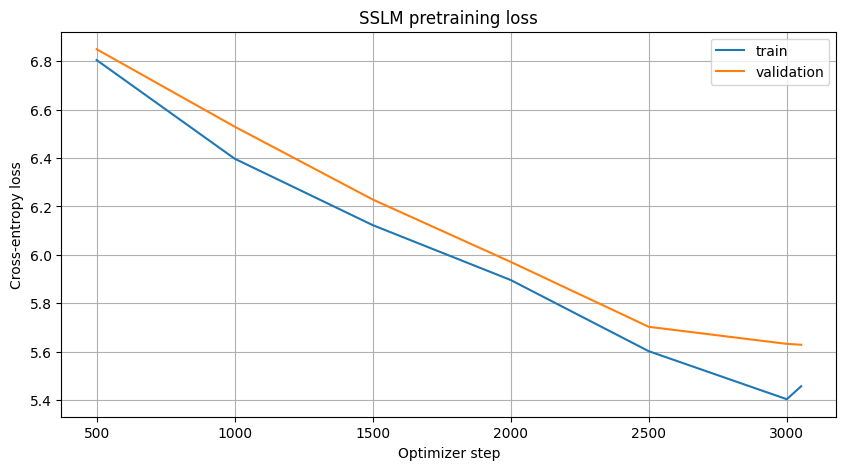

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="train")
plt.plot(history["step"], history["val_loss"], label="validation")
plt.xlabel("Optimizer step"); plt.ylabel("Cross-entropy loss")
plt.title("SSLM pretraining loss"); plt.legend(); plt.grid(True)
plt.show()

## 14. Load the best pretrained weights
For SFT, load the best validation checkpoint rather than the most recent checkpoint.

In [14]:
best_path = CKPT_DIR / "best_pretrain.pt"
if best_path.exists():
    best_ckpt = torch.load(best_path, map_location="cpu", weights_only=False)
    model.load_state_dict(best_ckpt["model"])
    print("Loaded best pretraining checkpoint. Validation loss:", best_ckpt["best_val"])
else:
    raise FileNotFoundError("best_pretrain.pt not found. Complete pretraining first.")

Loaded best pretraining checkpoint. Validation loss: 5.628065840403239


## 15. Conversational datasets
UltraChat supplies multi-turn conversations. OASST1 is converted into prompt/response examples using parent-child message links. We keep English OASST1 messages and only use assistant replies whose parent is a prompter message.

In [15]:
ultra = load_dataset("HuggingFaceH4/ultrachat_200k", split="train_sft")
oasst = load_dataset("OpenAssistant/oasst1", split="train")

print("UltraChat columns:", ultra.column_names)
print("OASST1 columns:", oasst.column_names)

README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

data/train_sft-00000-of-00003-a3ecf92756(…): reconstructing file:   0%|          |  0.00B /  244MB            

data/train_sft-00000-of-00003-a3ecf92756(…): downloading bytes:           |  0.00B            

data/train_sft-00001-of-00003-0a1804bcb6(…): reconstructing file:   0%|          |  0.00B /  244MB            

data/train_sft-00001-of-00003-0a1804bcb6(…): downloading bytes:           |  0.00B            

data/train_sft-00002-of-00003-ee46ed25cf(…): reconstructing file:   0%|          |  0.00B /  244MB            

... (19 outputs left out)

data/validation-00000-of-00001-134b8fd0c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/84437 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4401 [00:00<?, ? examples/s]

UltraChat columns: ['prompt', 'prompt_id', 'messages']
OASST1 columns: ['message_id', 'parent_id', 'user_id', 'created_date', 'text', 'role', 'lang', 'review_count', 'review_result', 'deleted', 'rank', 'synthetic', 'model_name', 'detoxify', 'message_tree_id', 'tree_state', 'emojis', 'labels']


## 16. Normalize conversations into message lists

In [16]:
def normalize_ultrachat(row):
    msgs = row.get("messages")
    if not isinstance(msgs, list):
        return None
    out = []
    for m in msgs:
        role = m.get("role")
        content = clean_text(m.get("content", ""))
        if role in ("system", "user", "assistant") and content:
            out.append({"role": role, "content": content})
    return out if len(out) >= 2 else None

ultra_conversations = []
for row in tqdm(ultra, desc="Preparing UltraChat"):
    conv = normalize_ultrachat(row)
    if conv and any(m["role"] == "assistant" for m in conv):
        ultra_conversations.append(conv)

# Reconstruct one-turn examples from OASST1 parent-child links.
oasst_rows = {}
for row in tqdm(oasst, desc="Indexing OASST1"):
    mid = row.get("message_id")
    if mid:
        oasst_rows[mid] = row

oasst_conversations = []
for mid, row in oasst_rows.items():
    if row.get("role") != "assistant" or row.get("lang") not in ("en", "English"):
        continue
    parent_id = row.get("parent_id")
    parent = oasst_rows.get(parent_id)
    if not parent or parent.get("role") != "prompter":
        continue
    prompt = clean_text(parent.get("text", ""))
    answer = clean_text(row.get("text", ""))
    if prompt and answer:
        oasst_conversations.append([
            {"role": "user", "content": prompt},
            {"role": "assistant", "content": answer}
        ])

print("UltraChat conversations:", len(ultra_conversations))
print("OASST1 prompt/reply examples:", len(oasst_conversations))

Preparing UltraChat:   0%|          | 0/207865 [00:00<?, ?it/s]

Indexing OASST1:   0%|          | 0/84437 [00:00<?, ?it/s]

UltraChat conversations: 207865
OASST1 prompt/reply examples: 24083


## 17. Train/validation split before tokenization and chunking
This prevents chunks from the same conversation leaking across train and validation. We use a deterministic split.

In [17]:
all_conversations = ultra_conversations + oasst_conversations
rng = random.Random(SEED)
rng.shuffle(all_conversations)
split_idx = max(1, int(0.98 * len(all_conversations)))
sft_train_convs = all_conversations[:split_idx]
sft_val_convs = all_conversations[split_idx:]
print("SFT train conversations:", len(sft_train_convs))
print("SFT validation conversations:", len(sft_val_convs))

SFT train conversations: 227309
SFT validation conversations: 4639


## 18. Encode assistant-only targets
User/system tokens are included as context but masked from the loss. The model is trained to predict assistant text and the EOS marker after each assistant turn.

In [18]:
PAD_ID = tokenizer.token_to_id("<|pad|>")
USER_ID = tokenizer.token_to_id("<|user|>")
ASSISTANT_ID = tokenizer.token_to_id("<|assistant|>")
SYSTEM_ID = tokenizer.token_to_id("<|system|>")

def encode_conversation(messages):
    ids, labels = [], []
    for m in messages:
        role = m["role"]
        if role == "user":
            prefix = [USER_ID]
            content_ids = tokenizer.encode(m["content"]).ids
            ids.extend(prefix + content_ids + [EOS_ID])
            labels.extend([-100] * (len(prefix) + len(content_ids) + 1))
        elif role == "system":
            prefix = [SYSTEM_ID]
            content_ids = tokenizer.encode(m["content"]).ids
            ids.extend(prefix + content_ids + [EOS_ID])
            labels.extend([-100] * (len(prefix) + len(content_ids) + 1))
        elif role == "assistant":
            prefix = [ASSISTANT_ID]
            content_ids = tokenizer.encode(m["content"]).ids
            segment = prefix + content_ids + [EOS_ID]
            ids.extend(segment)
            labels.extend([-100] + content_ids + [EOS_ID])
    return ids, labels

def make_sft_examples(conversations, max_len=MAX_SEQ_LEN):
    examples = []
    supervised = 0
    for conv in tqdm(conversations, desc="Encoding conversations"):
        ids, labels = encode_conversation(conv)
        # Split long conversations into context windows. Each chunk retains its masked labels.
        start = 0
        while start < len(ids):
            end = min(start + max_len, len(ids))
            x, y = ids[start:end], labels[start:end]
            if sum(t != -100 for t in y) >= 2:
                examples.append((x, y))
                supervised += sum(t != -100 for t in y)
            if end == len(ids): break
            start += max_len - 64  # overlap retains some conversational context
    return examples, supervised

sft_train_examples, sft_train_supervised = make_sft_examples(sft_train_convs)
sft_val_examples, sft_val_supervised = make_sft_examples(sft_val_convs)
print("Train chunks:", len(sft_train_examples), "assistant target tokens:", f"{sft_train_supervised:,}")
print("Val chunks:", len(sft_val_examples), "assistant target tokens:", f"{sft_val_supervised:,}")

Encoding conversations:   0%|          | 0/227309 [00:00<?, ?it/s]

Encoding conversations:   0%|          | 0/4639 [00:00<?, ?it/s]

Train chunks: 611197 assistant target tokens: 216,495,631
Val chunks: 12464 assistant target tokens: 4,388,777


## 19. Select the requested 8M assistant-token SFT budget

In [19]:
# Keep the target supervised assistant tokens at approximately 8M.
# Shuffle at the conversation/chunk level after the split; validation remains untouched.
rng = random.Random(SEED)
rng.shuffle(sft_train_examples)

selected = []
selected_tokens = 0
for ex in sft_train_examples:
    n = sum(t != -100 for t in ex[1])
    if selected_tokens >= SFT_TARGET_ASSISTANT_TOKENS:
        break
    selected.append(ex)
    selected_tokens += n

sft_train_examples = selected
print("Selected SFT chunks:", len(sft_train_examples))
print("Selected assistant target tokens:", f"{selected_tokens:,}")
if selected_tokens < SFT_TARGET_ASSISTANT_TOKENS:
    print("WARNING: dataset provided fewer than the requested target assistant tokens.")

Selected SFT chunks: 5607
Selected assistant target tokens: 2,000,424


## 20. Padding collator and SFT dataloaders

In [20]:
class SFTDataset(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, idx): return self.examples[idx]

def sft_collate(batch):
    max_len = max(len(x) for x, y in batch)
    xs, ys = [], []
    for x, y in batch:
        pad = max_len - len(x)
        xs.append(x + [PAD_ID] * pad)
        ys.append(y + [-100] * pad)
    return (torch.tensor(xs, dtype=torch.long),
            torch.tensor(ys, dtype=torch.long))

sft_train_loader = DataLoader(SFTDataset(sft_train_examples), batch_size=MICRO_BATCH_SIZE,
                              shuffle=True, collate_fn=sft_collate, num_workers=0)
sft_val_loader = DataLoader(SFTDataset(sft_val_examples), batch_size=MICRO_BATCH_SIZE,
                            shuffle=False, collate_fn=sft_collate, num_workers=0)

## 21. SFT optimizer and evaluation

In [21]:
SFT_LR = 5e-5
sft_optimizer = torch.optim.AdamW(model.parameters(), lr=SFT_LR, betas=(0.9, 0.95), weight_decay=0.01)

@torch.no_grad()
def evaluate_sft(loader, max_batches=100):
    model.eval()
    losses = []
    for i, (x, y) in enumerate(loader):
        if i >= max_batches: break
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16 if use_bf16 else torch.float16):
            _, loss = model(x, y)
        if loss is not None and torch.isfinite(loss):
            losses.append(loss.item())
    model.train()
    return float(np.mean(losses)) if losses else float("nan")

## 22. Conversational fine-tuning
The loss is calculated only on assistant response tokens. We use gradient accumulation and save checkpoints after every epoch and every 500 optimizer updates.

In [22]:
SFT_GRAD_ACCUM = GRAD_ACCUM_STEPS
SFT_SAVE_INTERVAL = 500
sft_history = {"step": [], "train_loss": [], "val_loss": []}
global_sft_step = 0
model.train()
sft_optimizer.zero_grad(set_to_none=True)

for epoch in range(SFT_EPOCHS):
    pbar = tqdm(enumerate(sft_train_loader), total=len(sft_train_loader), desc=f"SFT epoch {epoch+1}/{SFT_EPOCHS}")
    accum_loss = 0.0
    accum_count = 0
    for batch_idx, (x, y) in pbar:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16 if use_bf16 else torch.float16):
            _, loss = model(x, y)
            loss = loss / SFT_GRAD_ACCUM
        if scaler.is_enabled(): scaler.scale(loss).backward()
        else: loss.backward()
        accum_loss += loss.item() * SFT_GRAD_ACCUM
        accum_count += 1

        if accum_count == SFT_GRAD_ACCUM or batch_idx == len(sft_train_loader) - 1:
            if scaler.is_enabled(): scaler.unscale_(sft_optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            if scaler.is_enabled():
                scaler.step(sft_optimizer); scaler.update()
            else:
                sft_optimizer.step()
            sft_optimizer.zero_grad(set_to_none=True)
            global_sft_step += 1
            pbar.set_postfix(loss=f"{accum_loss/max(1,accum_count):.4f}")
            accum_loss, accum_count = 0.0, 0

            if global_sft_step % SFT_SAVE_INTERVAL == 0:
                torch.save({
                    "phase": "sft", "epoch": epoch, "step": global_sft_step,
                    "model": model.state_dict(), "optimizer": sft_optimizer.state_dict(),
                    "config": model.config
                }, CKPT_DIR / "latest_sft.pt")

    val_loss = evaluate_sft(sft_val_loader)
    sft_history["step"].append(global_sft_step)
    sft_history["val_loss"].append(val_loss)
    print(f"End epoch {epoch+1}: validation loss={val_loss:.4f}")
    torch.save({
        "phase": "sft", "epoch": epoch, "step": global_sft_step,
        "model": model.state_dict(), "optimizer": sft_optimizer.state_dict(),
        "val_loss": val_loss, "config": model.config
    }, CKPT_DIR / f"sft_epoch_{epoch+1}.pt")
    torch.save(model.state_dict(), CKPT_DIR / "best_chat_model_state_dict.pt")

with open(OUTPUT_DIR / "sft_history.json", "w") as f:
    json.dump(sft_history, f)

SFT epoch 1/1:   0%|          | 0/2804 [00:00<?, ?it/s]

End epoch 1: validation loss=4.6011


## 23. Plot SFT validation loss

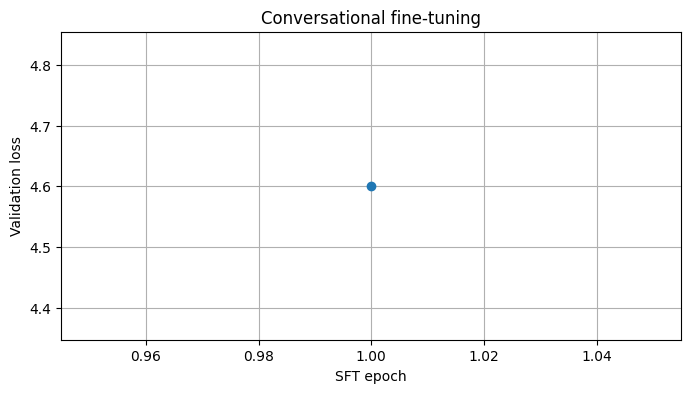

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(sft_history["val_loss"])+1), sft_history["val_loss"], marker="o")
plt.xlabel("SFT epoch"); plt.ylabel("Validation loss")
plt.title("Conversational fine-tuning"); plt.grid(True); plt.show()

## 24. Generation and chat
The model uses the `<|user|>` and `<|assistant|>` markers learned during SFT. This simple generation function recomputes the full context for each new token; it is suitable for testing but not optimized streaming inference.

In [24]:
@torch.no_grad()
def generate(prompt, max_new_tokens=160, temperature=0.8, top_k=40):
    model.eval()
    prompt_ids = [USER_ID] + tokenizer.encode(prompt).ids + [EOS_ID, ASSISTANT_ID]
    x = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        x_cond = x[:, -MAX_SEQ_LEN:]
        with torch.autocast("cuda", dtype=torch.bfloat16 if use_bf16 else torch.float16):
            logits, _ = model(x_cond)
        next_logits = logits[0, -1].float() / max(temperature, 1e-5)
        if top_k is not None:
            vals, _ = torch.topk(next_logits, min(top_k, next_logits.numel()))
            next_logits[next_logits < vals[-1]] = -float("inf")
        probs = F.softmax(next_logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1).item()
        if next_id == EOS_ID:
            break
        x = torch.cat([x, torch.tensor([[next_id]], device=DEVICE)], dim=1)
    generated = x[0, len(prompt_ids):].tolist()
    return tokenizer.decode(generated)

print(generate("Explain what a state space model is in simple terms.", max_new_tokens=120))

Yes, you can use a variety of features such as traditional and fiber, while the size of the top (and the recipe used by a new "Try." - The image of "Lost" in a single list of two "Vit" for "Mid" by "" and "The E-2" by Dr. C. L. (D. T. "The B.Pur" (F) - "("Festa) - "The author" (Buritl), "Ef" in H, N.M., B.


## 25. Interactive chat loop

In [25]:
chat_history = []
def chat_once(user_text):
    prompt = ""
    for role, content in chat_history[-6:]:
        marker = "<|user|>" if role == "user" else "<|assistant|>"
        prompt += marker + content + "<|endoftext|>"
    prompt += "<|user|>" + user_text + "<|endoftext|><|assistant|>"
    ids = tokenizer.encode(prompt).ids
    x = torch.tensor([ids], dtype=torch.long, device=DEVICE)
    model.eval()
    with torch.no_grad():
        for _ in range(180):
            with torch.autocast("cuda", dtype=torch.bfloat16 if use_bf16 else torch.float16):
                logits, _ = model(x[:, -MAX_SEQ_LEN:])
            next_logits = logits[0, -1].float() / 0.8
            vals, _ = torch.topk(next_logits, 40)
            next_logits[next_logits < vals[-1]] = -float("inf")
            nxt = torch.multinomial(F.softmax(next_logits, dim=-1), 1).item()
            if nxt == EOS_ID: break
            x = torch.cat([x, torch.tensor([[nxt]], device=DEVICE)], dim=1)
    answer = tokenizer.decode(x[0, len(ids):].tolist()).strip()
    chat_history.extend([("user", user_text), ("assistant", answer)])
    return answer

print("Chat ready. Type 'exit' to stop.")
while True:
    user_text = input("You: ").strip()
    if user_text.lower() in {"exit", "quit"}: break
    print("SSLM:", chat_once(user_text))

Chat ready. Type 'exit' to stop.


You:  hello


SSLM: Yes, who are a few examples of the unique and cultural heritage that has helped to learn in this world. In addition, the group's commitment to the traditional art and identity of the world's lives and support and are not enough to become a world of the world.


You:  who are you


SSLM: Sure, here are some examples: 1. [Your Name] - A book that works best known for the most popular language. 3. What's it? [Injart]: The author is a part of a world that has a few examples: 1. "Pa" of the American War - the "The New England" by The American Society (10:15-50), The Uzhana.


You:  exit


## 26. Export final model, tokenizer, and config
The export contains the fine-tuned weights and tokenizer. The full checkpoint includes optimizer states and is much larger; the compact state dict is more convenient for inference.

In [26]:
FINAL_DIR = OUTPUT_DIR / "sslm-100m-chat"
FINAL_DIR.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), FINAL_DIR / "model_state_dict.pt")
shutil.copy2(TOKENIZER_PATH, FINAL_DIR / "tokenizer.json")
with open(FINAL_DIR / "config.json", "w") as f:
    json.dump({
        "model_type": "diagonal_lti_ssm",
        "vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_layers": N_LAYERS,
        "d_state": D_STATE, "expansion": EXPANSION, "max_seq_len": MAX_SEQ_LEN,
        "parameter_count": n_params,
        "special_tokens": SPECIAL_TOKENS
    }, f, indent=2)
print("Exported to:", FINAL_DIR)

Exported to: /kaggle/working/sslm/outputs/sslm-100m-chat


## 27. Kaggle persistence checklist
1. At the end of a session, use **Save Version** and ensure notebook outputs are saved.
2. For reliable multi-session training, publish `/kaggle/working/sslm/checkpoints`, `data`, and `tokenizer` as a private Kaggle Dataset (or copy them to persistent storage).
3. In the next session, attach that Dataset under Notebook **Add Input**, then set `RESUME_FROM` to its `latest_pretrain.pt` path and restore the token files/tokenizer from the attached input.
4. If resuming pretraining, also restore `train.bin`, `val.bin`, and `tokenizer.json` to the paths configured above before running Cells 7–12. If resuming SFT, restore the final pretraining weights and rerun the SFT data preparation cells, or restore `latest_sft.pt` and load its model/optimizer state.
5. Do not delete `best_pretrain.pt`, `latest_pretrain.pt`, `best_chat_model_state_dict.pt`, or the final export.

**Compute note:** Actual wall-clock time depends heavily on whether Kaggle assigns a T4, P100, or L4 and on session quotas. The full 500M-token run may require many sessions. This notebook saves checkpoints, but Kaggle's `/working` directory itself is not persistent across sessions.